Program 2: Classical and Distributed Word Representation Techniques

Aim :
To construct Bag-of-Words and TF-IDF representations and compare them with Word2Vec or GloVe embeddings for similarity and downstream classification.


Problem Statement :
News Topic Similarity and Routing: A digital news desk wants related stories grouped and incoming articles routed to World, Sports, Business, or Science/Technology. Students represent AG News descriptions with BoW, TF-IDF, and Word2Vec, compare document similarity, and train the same classifier on each representation.


Software Requirements :
•	Python 3.x,
•	Scikit-learn,
•	Gensim,
•	NumPy and Pandas,
•	Matplotlib or Seaborn



Suggested Dataset :
Hugging Face Datasets — AG News, with four balanced news categories. Dataset page:
https://huggingface.co/datasets/fancyzhx/ag_news


Dataset Access -
Load directly: from datasets import load_dataset; ds = load_dataset("fancyzhx/ag_news"). No Kaggle account or manual extraction is required.


Recommended Lab Subset :
Use 8,000 stratified training records and 2,000 test records; use smaller samples if laboratory hardware is limited.


Procedure :                                                       
Step 1: Prepare the corpus
•	Apply the preprocessing pipeline from Program 1.
•	Split data into training and testing sets using stratification where applicable.


Step 2: Create Bag-of-Words features
•	Fit CountVectorizer on training data only.
•	Inspect vocabulary size, sparse matrix shape, and frequent terms.


Step 3: Create TF-IDF features
•	Fit TfidfVectorizer using unigram and optional bigram features.
•	Inspect high-weight terms for representative documents.


Step 4: Create distributed embeddings
•	Train Word2Vec using CBOW or Skip-gram, or load suitable pretrained GloVe vectors.
•	Create document vectors by averaging token embeddings.


Step 5: Analyse similarity
•	Compute cosine similarity for selected word and document pairs.


Step 6: Compare representations
•	Train the same baseline classifier on BoW, TF-IDF, and averaged embeddings.
•	Compare accuracy or F1-score, dimensionality, sparsity, training time, and out-of-vocabulary behaviour.


Expected Result :
A documented comparison of sparse and distributed representations using similarity examples and classification metrics.


Observations to Record :
•	Dataset size and split details.
•	Preprocessing and model configuration.
•	Evaluation metrics and sample outputs.


Viva Voce Questions

1.	Why is TF-IDF less dominated by frequent words than BoW?

2.	What is the difference between CBOW and Skip-gram?

3.	How are document vectors derived from word vectors?

4.	What is the out-of-vocabulary problem?

In [1]:
!pip install -q datasets gensim scikit-learn pandas numpy matplotlib seaborn

In [2]:
import re
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from gensim.models import Word2Vec

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


Load the AG News dataset

In [3]:
# Load AG News dataset
ds = load_dataset("fancyzhx/ag_news")

# Convert dataset into Pandas DataFrames
train_df = pd.DataFrame(ds["train"])
test_df = pd.DataFrame(ds["test"])

# Category names
category_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Science/Technology"
}

print("Dataset loaded successfully!")

print("\nOriginal Training Dataset Shape:", train_df.shape)
print("Original Testing Dataset Shape:", test_df.shape)

# Select stratified samples
train_df, _ = train_test_split(
    train_df,
    train_size=8000,
    stratify=train_df["label"],
    random_state=42
)

test_df, _ = train_test_split(
    test_df,
    train_size=2000,
    stratify=test_df["label"],
    random_state=42
)

# Reset index
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nSelected Training Records:", len(train_df))
print("Selected Testing Records:", len(test_df))

print("\nTraining Category Distribution:")
print(train_df["label"].value_counts().sort_index().rename(index=category_names))

print("\nTesting Category Distribution:")
print(test_df["label"].value_counts().sort_index().rename(index=category_names))

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Dataset loaded successfully!

Original Training Dataset Shape: (120000, 2)
Original Testing Dataset Shape: (7600, 2)

Selected Training Records: 8000
Selected Testing Records: 2000

Training Category Distribution:
label
World                 2000
Sports                2000
Business              2000
Science/Technology    2000
Name: count, dtype: int64

Testing Category Distribution:
label
World                 500
Sports                500
Business              500
Science/Technology    500
Name: count, dtype: int64


Text preprocessing

In [4]:
def preprocess_text(text):
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
train_df["clean_text"] = train_df["text"].apply(preprocess_text)
test_df["clean_text"] = test_df["text"].apply(preprocess_text)

# Tokenization
train_tokens = [text.split() for text in train_df["clean_text"]]
test_tokens = [text.split() for text in test_df["clean_text"]]

X_train_text = train_df["clean_text"]
X_test_text = test_df["clean_text"]

y_train = train_df["label"]
y_test = test_df["label"]

print("Preprocessing completed successfully!")

print("\nOriginal Text:")
print(train_df["text"][0])

print("\nPreprocessed Text:")
print(train_df["clean_text"][0])

print("\nTokenized Words:")
print(train_tokens[0])

Preprocessing completed successfully!

Original Text:
Call for bandit death inquiry A leading human rights group in India questions why police had to kill the country's most notorious bandit, Veerappan.

Preprocessed Text:
call for bandit death inquiry a leading human rights group in india questions why police had to kill the country s most notorious bandit veerappan

Tokenized Words:
['call', 'for', 'bandit', 'death', 'inquiry', 'a', 'leading', 'human', 'rights', 'group', 'in', 'india', 'questions', 'why', 'police', 'had', 'to', 'kill', 'the', 'country', 's', 'most', 'notorious', 'bandit', 'veerappan']


Create Bag-of-Words representation

Bag-of-Words Representation Created!

Vocabulary Size: 10000
Training Matrix Shape: (8000, 10000)
Testing Matrix Shape: (2000, 10000)

Top 20 Frequent Words:
   Word  Frequency
    the      13845
     to       8044
     of       6717
     in       6448
    and       4708
     on       3681
    for       3414
   that       1963
   with       1809
     as       1767
     at       1719
     is       1478
    its       1473
     it       1433
    new       1420
   said       1355
     by       1352
    has       1290
reuters       1191
   from       1169


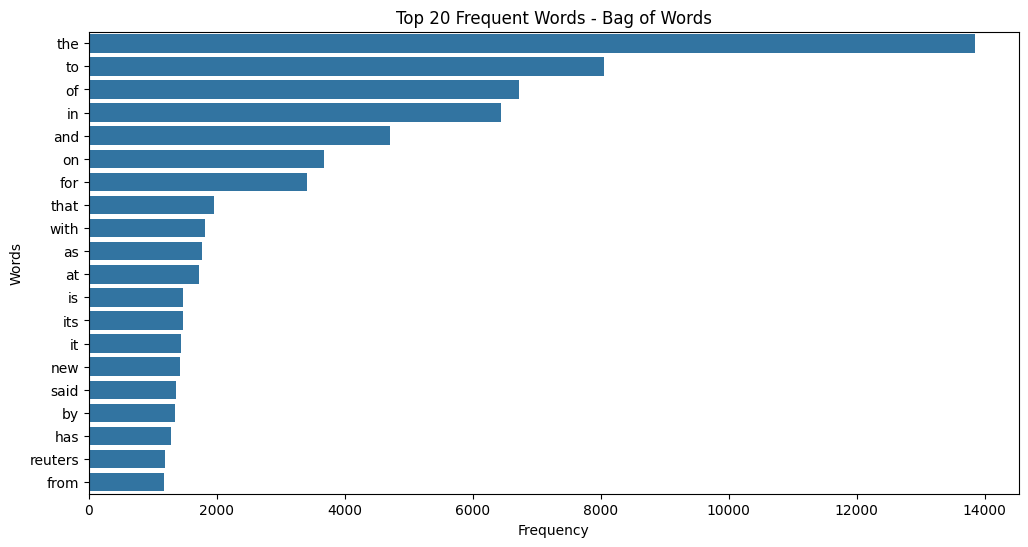

In [5]:
# Create Bag-of-Words model
bow_vectorizer = CountVectorizer(
    max_features=10000,
    ngram_range=(1, 1)
)

# Fit only on training data
X_train_bow = bow_vectorizer.fit_transform(X_train_text)

# Transform testing data
X_test_bow = bow_vectorizer.transform(X_test_text)

print("Bag-of-Words Representation Created!")

print("\nVocabulary Size:", len(bow_vectorizer.vocabulary_))
print("Training Matrix Shape:", X_train_bow.shape)
print("Testing Matrix Shape:", X_test_bow.shape)

# Display most frequent words
word_counts = np.asarray(X_train_bow.sum(axis=0)).flatten()

bow_words = bow_vectorizer.get_feature_names_out()

frequency_df = pd.DataFrame({
    "Word": bow_words,
    "Frequency": word_counts
})

frequency_df = frequency_df.sort_values(
    by="Frequency",
    ascending=False
)

print("\nTop 20 Frequent Words:")
print(frequency_df.head(20).to_string(index=False))

# Plot frequent words
plt.figure(figsize=(12, 6))

sns.barplot(
    data=frequency_df.head(20),
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Frequent Words - Bag of Words")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.show()

Create TF-IDF representation

In [6]:
# Create TF-IDF model
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

# Fit on training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)

# Transform testing data
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("TF-IDF Representation Created!")

print("\nVocabulary Size:", len(tfidf_vectorizer.vocabulary_))
print("Training Matrix Shape:", X_train_tfidf.shape)
print("Testing Matrix Shape:", X_test_tfidf.shape)

# Display important terms in first document
tfidf_scores = X_train_tfidf[0].toarray().flatten()

tfidf_words = tfidf_vectorizer.get_feature_names_out()

top_indices = np.argsort(tfidf_scores)[::-1][:10]

print("\nTop 10 TF-IDF Terms in First Document:")

for index in top_indices:
    if tfidf_scores[index] > 0:
        print(
            tfidf_words[index],
            ":", round(tfidf_scores[index], 4)
        )

TF-IDF Representation Created!

Vocabulary Size: 10000
Training Matrix Shape: (8000, 10000)
Testing Matrix Shape: (2000, 10000)

Top 10 TF-IDF Terms in First Document:
group in : 0.257
rights group : 0.257
notorious : 0.2498
to kill : 0.2438
had to : 0.2388
call for : 0.2345
inquiry : 0.2241
human rights : 0.2227
in india : 0.2187
questions : 0.2152


Create Word2Vec distributed embeddings

In [7]:
# Train Word2Vec Skip-gram model
start_time = time.time()

word2vec_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=2,
    sg=1,
    epochs=10,
    seed=42
)

word2vec_training_time = time.time() - start_time

print("Word2Vec Model Trained Successfully!")

print("\nVocabulary Size:", len(word2vec_model.wv))
print("Vector Dimensions:", word2vec_model.vector_size)

print(
    "Word2Vec Training Time:",
    round(word2vec_training_time, 2),
    "seconds"
)

# Display word vector
word = "government"

if word in word2vec_model.wv:
    print("\nWord Vector for:", word)
    print(word2vec_model.wv[word])

else:
    print("\nWord not found in Word2Vec vocabulary.")

Word2Vec Model Trained Successfully!

Vocabulary Size: 13258
Vector Dimensions: 100
Word2Vec Training Time: 21.27 seconds

Word Vector for: government
[ 1.0348275   0.3843928  -0.27564794 -0.15483573 -0.16007107  0.06895333
  0.16194192  0.17207006 -0.37280628 -0.29143348 -0.5712593   0.17696011
 -0.07492882 -0.28577355 -0.20901574  0.05674904 -0.06480177 -0.7982834
 -0.37895453  0.21066457  0.1445099   0.13733171  0.14666384  0.02391638
  0.5055633   0.04780823  0.48711094  0.276186   -0.61632854  0.34919804
  0.08318106 -0.02060771  0.1839923  -0.14477503 -0.26690912  0.08812351
  0.33138415 -0.7753186   0.46470672  0.28348646  0.13959742  0.13214351
  0.37244812 -0.46132612  0.12302444  0.0586672  -0.04056082  0.36867255
  0.29046535 -0.48922753  0.2264024  -0.38785702 -0.6007928  -0.24224709
 -0.37352005 -0.34236208 -0.02586844  0.4712378   0.00627498  0.6417941
 -0.35393402  0.08278927  0.17912427  0.15733096  0.2357435   0.08221162
  0.3786401   0.03846325 -0.46031636 -0.5616143 

Create document vectors using Word2Vec

In [8]:
def document_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Create training document vectors
X_train_w2v = np.array([
    document_vector(tokens, word2vec_model)
    for tokens in train_tokens
])

# Create testing document vectors
X_test_w2v = np.array([
    document_vector(tokens, word2vec_model)
    for tokens in test_tokens
])

print("Word2Vec Document Vectors Created!")

print("\nTraining Shape:", X_train_w2v.shape)
print("Testing Shape:", X_test_w2v.shape)

# Calculate OOV (Out Of Vocabulary) rate
total_test_words = sum(len(tokens) for tokens in test_tokens)

oov_words = sum(
    1
    for tokens in test_tokens
    for word in tokens
    if word not in word2vec_model.wv
)

oov_rate = (oov_words / total_test_words) * 100

print("\nTotal Test Words:", total_test_words)
print("OOV Words:", oov_words)
print("OOV Rate:", round(oov_rate, 2), "%")

Word2Vec Document Vectors Created!

Training Shape: (8000, 100)
Testing Shape: (2000, 100)

Total Test Words: 76330
OOV Words: 4386
OOV Rate: 5.75 %


Word similarity and nearest neighbours

In [9]:
# Word similarity
word_pairs = [
    ("government", "president"),
    ("football", "sport"),
    ("company", "business"),
    ("computer", "technology"),
    ("market", "economy")
]

print("WORD SIMILARITY RESULTS\n")

for word1, word2 in word_pairs:

    if word1 in word2vec_model.wv and word2 in word2vec_model.wv:

        similarity = word2vec_model.wv.similarity(
            word1, word2
        )

        print(
            word1,
            "<->",
            word2,
            ":",
            round(similarity, 4)
        )

    else:
        print(word1, "or", word2, "not found in vocabulary")


# Find nearest neighbours
target_word = "government"

if target_word in word2vec_model.wv:

    print("\nNearest Neighbours of", target_word)

    for word, score in word2vec_model.wv.most_similar(
        target_word,
        topn=10
    ):
        print(word, ":", round(score, 4))

WORD SIMILARITY RESULTS

government <-> president : 0.2988
football <-> sport : 0.5455
company <-> business : 0.4536
computer <-> technology : 0.5747
market <-> economy : 0.5475

Nearest Neighbours of government
nigerian : 0.6879
facilities : 0.6837
ransom : 0.6798
cabinet : 0.677
expressed : 0.6727
interference : 0.6697
kuwaiti : 0.6672
renewed : 0.6671
congress : 0.6625
contracts : 0.6619


Document similarity using cosine similarity

DOCUMENT SIMILARITY COMPARISON

Document 1:
Mars Rovers Relay Images Through Mars Express European Space Agency -- ESAs Mars Express has relayed pictures from one of NASA's Mars rovers for the first time, as part of a set of interplanetary networking demonstrations.     The demonstrations pave the way for future Mars missions to draw on joint interplanetary networking capabilities...

Document 2:
Federated Department Stores Posts Profit  NEW YORK (Reuters) - Federated Department Stores Inc.  &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=FD.N target=/stocks/quickinfo/fullquote"&gt;FD.N&lt;/A&gt;, parent of Macy's and Bloomingdale's, posted  higher-than-expected quarterly earnings on Wednesday, as the  company rebounded from the Florida hurricanes.

Document 1 Category: Science/Technology
Document 2 Category: Business

Cosine Similarity Scores:
Bag-of-Words: 0.1711
TF-IDF: 0.0139
Word2Vec: 0.7016


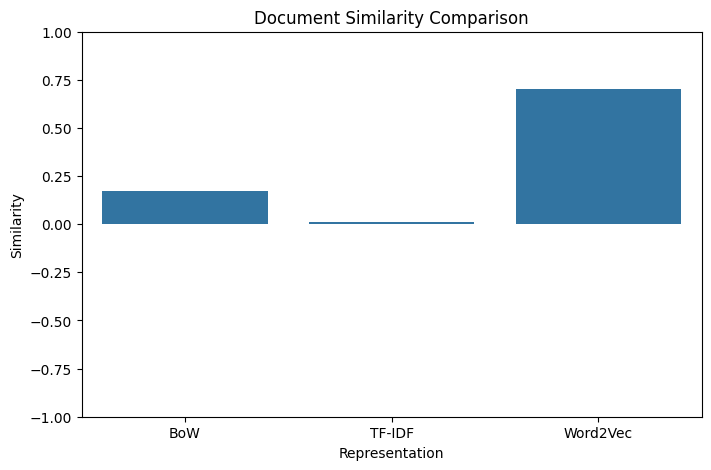

In [10]:
# Select two news articles
doc1 = 0
doc2 = 1

# Bag-of-Words similarity
bow_similarity = cosine_similarity(
    X_test_bow[doc1],
    X_test_bow[doc2]
)[0][0]

# TF-IDF similarity
tfidf_similarity = cosine_similarity(
    X_test_tfidf[doc1],
    X_test_tfidf[doc2]
)[0][0]

# Word2Vec similarity
w2v_similarity = cosine_similarity(
    X_test_w2v[doc1].reshape(1, -1),
    X_test_w2v[doc2].reshape(1, -1)
)[0][0]

print("DOCUMENT SIMILARITY COMPARISON\n")

print("Document 1:")
print(test_df["text"][doc1])

print("\nDocument 2:")
print(test_df["text"][doc2])

print("\nDocument 1 Category:",
      category_names[y_test.iloc[doc1]])

print("Document 2 Category:",
      category_names[y_test.iloc[doc2]])

print("\nCosine Similarity Scores:")

print("Bag-of-Words:", round(bow_similarity, 4))
print("TF-IDF:", round(tfidf_similarity, 4))
print("Word2Vec:", round(w2v_similarity, 4))


# Plot similarity comparison
similarity_df = pd.DataFrame({
    "Representation": ["BoW", "TF-IDF", "Word2Vec"],
    "Similarity": [
        bow_similarity,
        tfidf_similarity,
        w2v_similarity
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=similarity_df,
    x="Representation",
    y="Similarity"
)

plt.title("Document Similarity Comparison")
plt.ylim(-1, 1)
plt.show()

Train the same classifier on all representations

In [11]:
results = []

representations = {
    "Bag-of-Words": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v, X_test_w2v)
}

models = {}

for name, (X_train, X_test) in representations.items():

    print("\nTraining:", name)

    start_time = time.time()

    # Same classifier for all representations
    model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Predictions
    y_pred = model.predict(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    models[name] = model

    results.append({
        "Representation": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Training Time (seconds)": training_time,
        "Dimensions": X_train.shape[1]
    })

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=list(category_names.values()),
            zero_division=0
        )
    )

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("Training Time:", round(training_time, 2), "seconds")


Training: Bag-of-Words

Classification Report:
                    precision    recall  f1-score   support

             World       0.88      0.87      0.87       500
            Sports       0.94      0.94      0.94       500
          Business       0.82      0.81      0.82       500
Science/Technology       0.83      0.84      0.83       500

          accuracy                           0.87      2000
         macro avg       0.87      0.87      0.87      2000
      weighted avg       0.87      0.87      0.87      2000

Accuracy: 0.8665
Precision: 0.8664
Recall: 0.8665
F1-Score: 0.8664
Training Time: 3.55 seconds

Training: TF-IDF

Classification Report:
                    precision    recall  f1-score   support

             World       0.90      0.86      0.88       500
            Sports       0.93      0.96      0.95       500
          Business       0.86      0.82      0.84       500
Science/Technology       0.82      0.87      0.84       500

          accuracy            

Compare classification performance

In [12]:
results_df = pd.DataFrame(results)

print("CLASSIFICATION PERFORMANCE COMPARISON\n")

print(
    results_df.round(4).to_string(index=False)
)

# Identify best representation based on F1-score
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("\nBEST REPRESENTATION:")

print("Method:", best_model["Representation"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("F1-Score:", round(best_model["F1-Score"], 4))

CLASSIFICATION PERFORMANCE COMPARISON

Representation  Accuracy  Precision  Recall  F1-Score  Training Time (seconds)  Dimensions
  Bag-of-Words    0.8665     0.8664  0.8665    0.8664                   3.5484       10000
        TF-IDF    0.8760     0.8765  0.8760    0.8758                   2.7138       10000
      Word2Vec    0.8575     0.8571  0.8575    0.8571                   4.2140         100

BEST REPRESENTATION:
Method: TF-IDF
Accuracy: 0.876
F1-Score: 0.8758


Compare sparsity and dimensionality

In [13]:
def calculate_sparsity(matrix):
    total_elements = matrix.shape[0] * matrix.shape[1]

    if hasattr(matrix, "nnz"):
        nonzero_elements = matrix.nnz
    else:
        nonzero_elements = np.count_nonzero(matrix)

    sparsity = (
        1 - nonzero_elements / total_elements
    ) * 100

    return sparsity


comparison = []

for name, (X_train, X_test) in representations.items():

    comparison.append({
        "Representation": name,
        "Dimensions": X_train.shape[1],
        "Training Records": X_train.shape[0],
        "Sparsity (%)": calculate_sparsity(X_train),
        "Storage Type": (
            "Sparse"
            if hasattr(X_train, "nnz")
            else "Dense"
        )
    })

comparison_df = pd.DataFrame(comparison)

print("DIMENSIONALITY AND SPARSITY COMPARISON\n")

print(comparison_df.round(2).to_string(index=False))

DIMENSIONALITY AND SPARSITY COMPARISON

Representation  Dimensions  Training Records  Sparsity (%) Storage Type
  Bag-of-Words       10000              8000         99.71       Sparse
        TF-IDF       10000              8000         99.64       Sparse
      Word2Vec         100              8000          0.00        Dense


Plot performance comparison

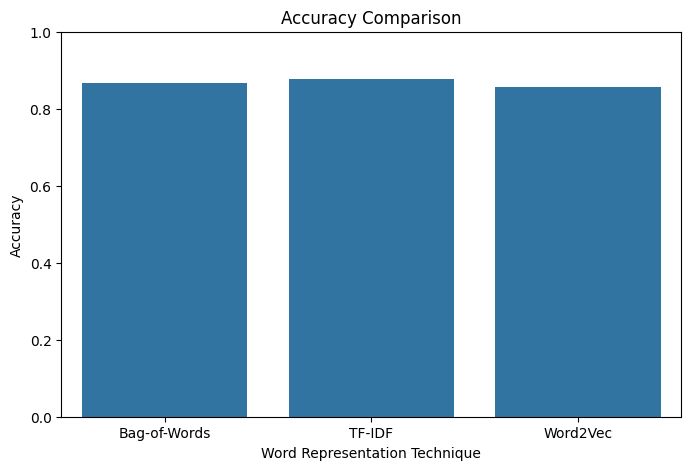

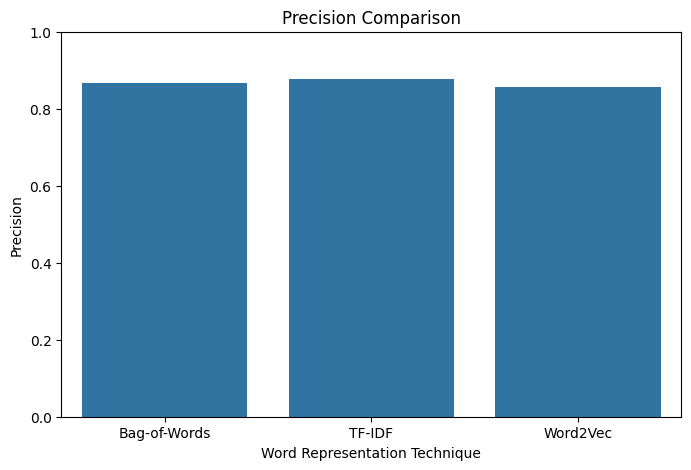

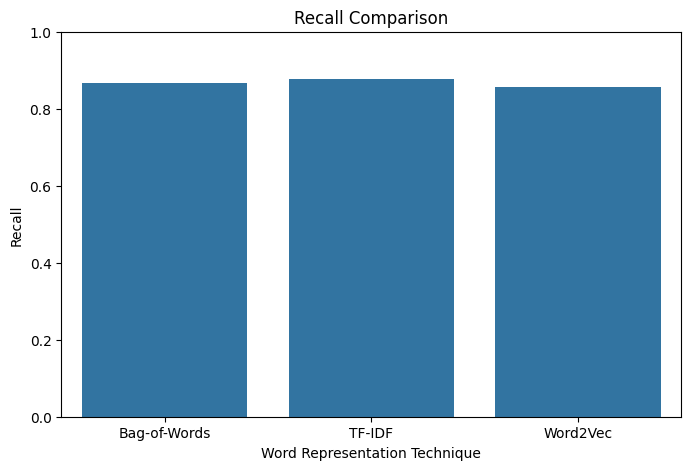

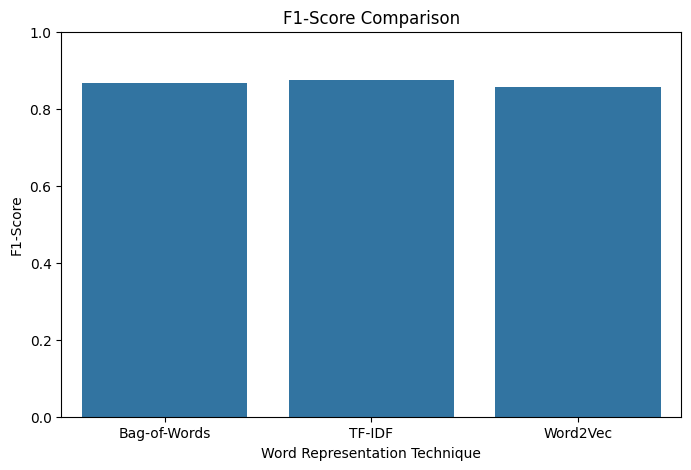

In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=results_df,
        x="Representation",
        y=metric
    )

    plt.title(metric + " Comparison")
    plt.xlabel("Word Representation Technique")
    plt.ylabel(metric)

    plt.ylim(0, 1)
    plt.show()

Plot training time comparison

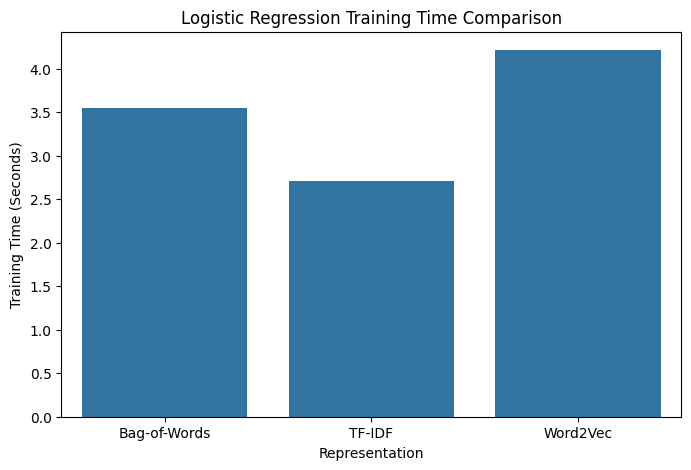

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Representation",
    y="Training Time (seconds)"
)

plt.title("Logistic Regression Training Time Comparison")
plt.xlabel("Representation")
plt.ylabel("Training Time (Seconds)")

plt.show()

Confusion matrix for the best model

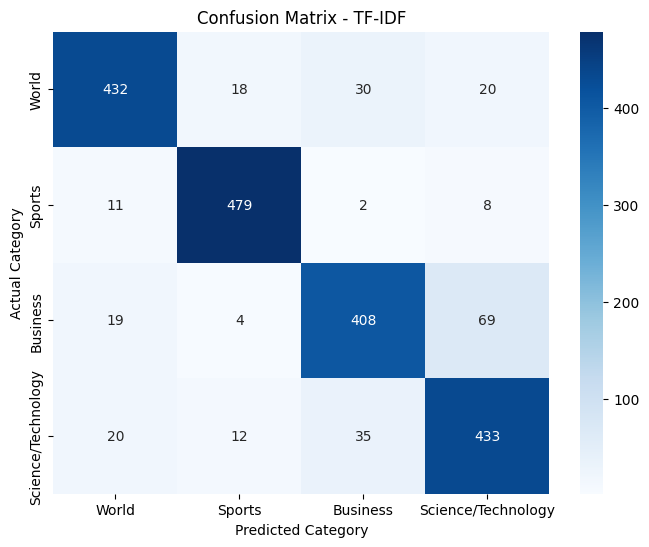

In [16]:
best_name = best_model["Representation"]

best_classifier = models[best_name]

X_test_best = representations[best_name][1]

y_pred_best = best_classifier.predict(X_test_best)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(category_names.values()),
    yticklabels=list(category_names.values())
)

plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

News topic routing

In [17]:
def route_news(news_article):

    cleaned_text = preprocess_text(news_article)

    # Transform using the selected representation
    if best_name == "Bag-of-Words":
        features = bow_vectorizer.transform([cleaned_text])

    elif best_name == "TF-IDF":
        features = tfidf_vectorizer.transform([cleaned_text])

    else:
        tokens = cleaned_text.split()

        vector = document_vector(
            tokens,
            word2vec_model
        )

        features = vector.reshape(1, -1)

    # Predict category
    prediction = best_classifier.predict(features)[0]

    return category_names[prediction]


# Test incoming news articles
news_articles = [
    "The government announced new international trade policies.",
    "The football team won the championship after a great match.",
    "The stock market reported significant growth in company shares.",
    "Scientists developed a new artificial intelligence technology."
]

print("NEWS TOPIC ROUTING RESULTS\n")

for article in news_articles:

    category = route_news(article)

    print("News:", article)
    print("Routed Category:", category)
    print("-" * 80)

NEWS TOPIC ROUTING RESULTS

News: The government announced new international trade policies.
Routed Category: Business
--------------------------------------------------------------------------------
News: The football team won the championship after a great match.
Routed Category: Sports
--------------------------------------------------------------------------------
News: The stock market reported significant growth in company shares.
Routed Category: Business
--------------------------------------------------------------------------------
News: Scientists developed a new artificial intelligence technology.
Routed Category: Science/Technology
--------------------------------------------------------------------------------


Final observations and conclusion

In [18]:
print("=" * 65)
print("FINAL PROGRAM RESULTS")
print("=" * 65)

print("\nDataset Information:")
print("Training Records:", len(train_df))
print("Testing Records:", len(test_df))
print("Number of Categories:", len(category_names))

print("\nRepresentation Comparison:")

print(results_df.round(4).to_string(index=False))

print("\nSparsity Comparison:")

print(comparison_df.round(2).to_string(index=False))

print("\nBest Performing Representation:")
print(best_name)

print("\nBest Accuracy:",
      round(best_model["Accuracy"] * 100, 2), "%")

print("Best F1-Score:",
      round(best_model["F1-Score"], 4))

print("\nWord2Vec OOV Rate:",
      round(oov_rate, 2), "%")

print("\nProgram Executed Successfully!")

FINAL PROGRAM RESULTS

Dataset Information:
Training Records: 8000
Testing Records: 2000
Number of Categories: 4

Representation Comparison:
Representation  Accuracy  Precision  Recall  F1-Score  Training Time (seconds)  Dimensions
  Bag-of-Words    0.8665     0.8664  0.8665    0.8664                   3.5484       10000
        TF-IDF    0.8760     0.8765  0.8760    0.8758                   2.7138       10000
      Word2Vec    0.8575     0.8571  0.8575    0.8571                   4.2140         100

Sparsity Comparison:
Representation  Dimensions  Training Records  Sparsity (%) Storage Type
  Bag-of-Words       10000              8000         99.71       Sparse
        TF-IDF       10000              8000         99.64       Sparse
      Word2Vec         100              8000          0.00        Dense

Best Performing Representation:
TF-IDF

Best Accuracy: 87.6 %
Best F1-Score: 0.8758

Word2Vec OOV Rate: 5.75 %

Program Executed Successfully!


•	Dataset size and split details.

The dataset used for this experiment is AG News, obtained from the Hugging Face Datasets library. It contains news articles belonging to four different categories: World, Sports, Business, and Science/Technology.

The original dataset contains 120,000 training records and 7,600 testing records. For this practical, a smaller stratified subset is selected to reduce computational requirements.

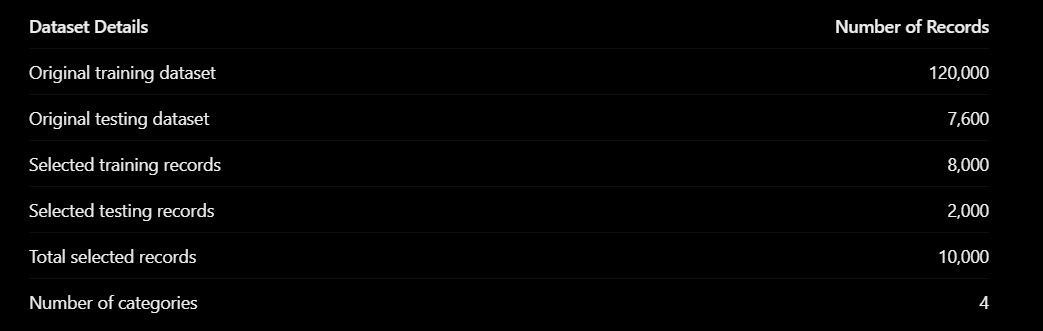

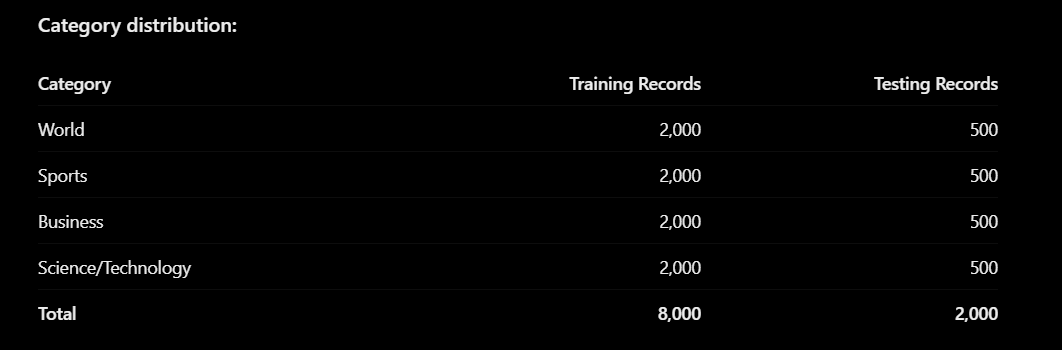

•	Preprocessing and model configuration.

The AG News dataset is preprocessed before applying the word representation techniques. The following preprocessing steps are performed:
1. Lowercase Conversion: All text is converted into lowercase to maintain consistency.
2. Special Character Removal: Special characters, punctuation and numbers are removed.
3. Whitespace Removal: Extra spaces are removed from the text.
4. Tokenization: News articles are split into individual words.
5. Training and Testing Split: The dataset is divided into 8,000 training records and 2,000 testing records using stratified sampling.

2. Model Configuration

The following configurations are used for implementing the three word representation techniques.

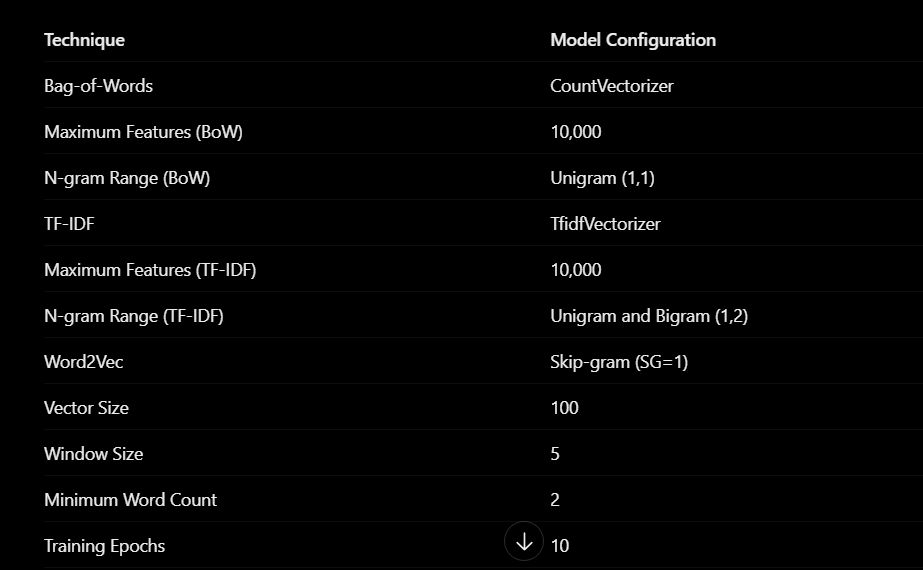

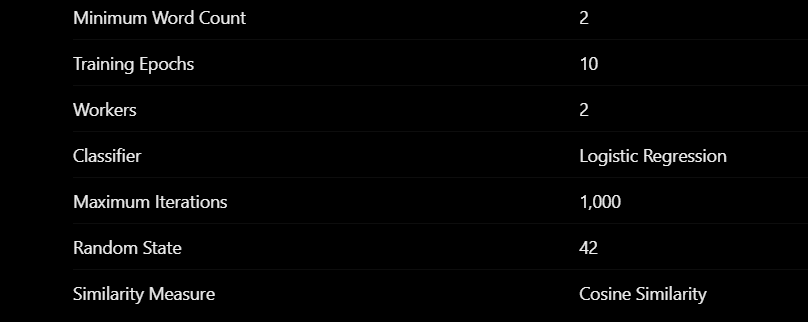

•	Evaluation metrics and sample outputs.

The performance of BoW, TF-IDF and Word2Vec is evaluated using Logistic Regression.

Evaluation Metrics:
- Accuracy – Overall classification correctness.
- Precision – Correct positive predictions.
- Recall – Correctly identified actual categories.
- F1-Score – Balance between precision and recall.
- Cosine Similarity – Similarity between news articles.
- Training Time – Time required to train the model.
- Sparsity and OOV Rate – Feature sparsity and unknown word percentage.
Sample News Routing Output:
News Article	Predicted Category
Government announces trade policies	World
Football team wins championship	Sports
Stock market shows growth	Business
Scientists develop AI technology	Science/Technology

Graphical Outputs:
- Word frequency graph.
- Similarity comparison graph.
- Classification performance graph.
- Confusion matrix.

•	Errors, limitations, ethical considerations, and proposed improvements.

1. Errors:
- Incorrect classification of some news articles.
- Unknown words may not be recognized by Word2Vec.
- Similar words may have different meanings depending on context.
2. Limitations:
- Word2Vec does not fully understand sentence context.
- BoW and TF-IDF do not capture semantic relationships effectively.
- Training performance depends on dataset size and hardware.
3. Ethical Considerations:
- Ensure news data is reliable and unbiased.
- Avoid spreading misinformation through incorrect classification.
- Protect user privacy and respect copyright.
4. Proposed Improvements:
- Use larger and more diverse datasets.
- Apply advanced models such as BERT.
- Improve text preprocessing.
- Use pretrained GloVe or Word2Vec embeddings.
- Tune model parameters to improve classification accuracy.

Viva Voce Questions



1.	Why is TF-IDF less dominated by frequent words than BoW?

TF-IDF is less dominated by frequent words than Bag-of-Words because it assigns lower weights to words that appear in many documents and higher weights to words that are more important and unique to a particular document.

2.	What is the difference between CBOW and Skip-gram?

CBOW (Continuous Bag of Words): Predicts the target word using its surrounding context words. It is generally faster to train.

Skip-gram: Predicts surrounding context words using the target word. It is generally better at learning representations for rare words but can take longer to train.

3.	How are document vectors derived from word vectors?

Document vectors are derived by averaging the word vectors (embeddings) of all the words in a document. Each word is converted into a numerical vector using Word2Vec, and the average of these vectors represents the entire document.

4.	What is the out-of-vocabulary problem?

The Out-of-Vocabulary (OOV) problem occurs when a model encounters a word that was not present in its training vocabulary. As a result, the model cannot find its corresponding word vector or properly process that word. It can be reduced by using larger datasets or subword-based models like FastText.